# Capitolo 3 — Feature locali e corrispondenze
Arcangelo Distante e Cosimo Distante — **Computer Vision**

Questo notebook usa esclusivamente segnali, punti e camere sintetici, definiti nel codice. Non contiene immagini esterne, benchmark, addestramento o misure di una camera reale. Le quantità calcolate illustrano i modelli e le loro condizioni di validità.

## Avvio e materiali
In Google Colab aprire questo file, selezionare un runtime **CPU** e avviare le celle dall’alto. Non servono GPU, file da caricare né download di dati. Sono necessarie NumPy e Matplotlib, normalmente già disponibili in Colab; in un ambiente nuovo installarle prima dell’esecuzione con `%pip install numpy matplotlib`. In locale è adeguato Python 3 con le stesse dipendenze.

La cartella `output_capitolo03` viene creata nello stesso runtime. Alla fine contiene figure, eventuali CSV e `metriche.json`. Per conservarla in Colab scaricarla dal pannello File prima di chiudere il runtime, oppure copiarla nel proprio Drive dopo averlo montato. Il riavvio elimina le variabili: rieseguire dalla prima cella. Per ogni esperimento modificato conservare parametri, seed e output in una nuova cartella.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

OUTPUT = Path('output_capitolo03')
OUTPUT.mkdir(exist_ok=True)
rng = np.random.default_rng(2026)
metriche = {}
plt.rcParams.update({'font.size': 10, 'figure.figsize': (7, 4)})

def salva_figura(nome):
    plt.tight_layout()
    plt.savefig(OUTPUT / (nome + '.png'), dpi=160)
    plt.show()
    plt.close()

def proietta(P, X):
    q = np.c_[X, np.ones(len(X))] @ P.T
    return q[:, :2] / q[:, 2:]


## N3.A1 — Due direzioni di variazione

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

rampa M = [[1. 0.]
 [0. 0.]] autovalori = [0. 1.]
corner M = [[0.02479339 0.00206612]
 [0.00206612 0.02479339]] autovalori = [0.02272727 0.0268595 ]


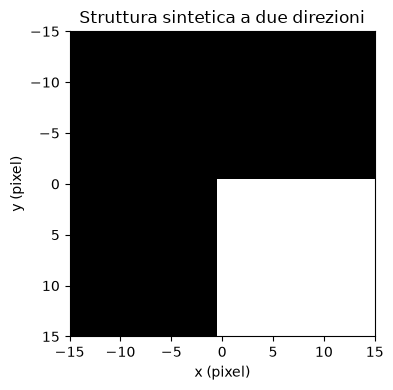

In [2]:
y, x = np.mgrid[-15:16, -15:16]
immagini = {'rampa': x.astype(float), 'corner': ((x>=0)&(y>=0)).astype(float)}
for nome, I in immagini.items():
    gy, gx = np.gradient(I)
    gx, gy = gx[10:21, 10:21], gy[10:21, 10:21]
    M = np.array([[np.mean(gx*gx), np.mean(gx*gy)],
                  [np.mean(gx*gy), np.mean(gy*gy)]])
    eig = np.linalg.eigvalsh(M)
    metriche['autovalori_'+nome] = eig.tolist()
    print(nome, 'M =', M, 'autovalori =', eig)
plt.imshow(immagini['corner'], cmap='gray', extent=(-15,15,15,-15))
plt.xlabel('x (pixel)'); plt.ylabel('y (pixel)')
plt.title('Struttura sintetica a due direzioni')
salva_figura('A1_corner')


**Domande**

1. Interpretare l’autovalore nullo della rampa.
2. Perché una soglia assoluta non permette qui di confrontare la forza dei due segnali senza considerarne la scala di intensità?

## N3.A2 — Scala caratteristica

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

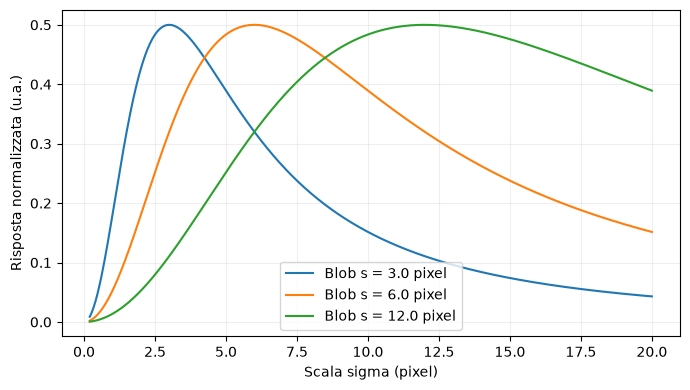

In [3]:
sigma = np.linspace(0.2, 20, 1000)
for s in [3., 6., 12.]:
    risposta = 2*s*s*sigma*sigma/(s*s+sigma*sigma)**2
    picco = float(sigma[np.argmax(risposta)])
    metriche['scala_stimata_blob_'+str(s)] = picco
    plt.plot(sigma, risposta, label=f'Blob s = {s} pixel')
plt.xlabel('Scala sigma (pixel)'); plt.ylabel('Risposta normalizzata (u.a.)')
plt.legend(); plt.grid(alpha=0.2)
salva_figura('A2_scala')


**Domande**

1. Confrontare il massimo campionato con quello analitico.
2. Spiegare perché il fattore sigma al quadrato è necessario nel confronto fra scale.

## N3.A3 — Ambiguità del primo vicino

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

ambiguo rapporto = 0.8 accettato = False
distinto rapporto = 0.22222222222222224 accettato = True


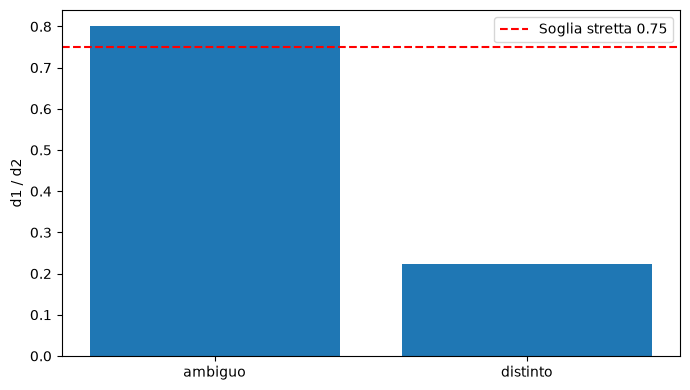

In [4]:
distanze = {'ambiguo': np.array([0.4, 0.5]), 'distinto': np.array([0.2, 0.9])}
soglia = 0.75
for nome, d in distanze.items():
    rapporto = float(d[0]/d[1])
    metriche['ratio_'+nome] = rapporto
    metriche['accettato_'+nome] = bool(rapporto < soglia)
    print(nome, 'rapporto =', rapporto, 'accettato =', rapporto < soglia)
plt.bar(list(distanze), [metriche['ratio_'+k] for k in distanze])
plt.axhline(soglia, color='red', linestyle='--', label='Soglia stretta 0.75')
plt.ylabel('d1 / d2'); plt.legend()
salva_figura('A3_ratio')


**Domande**

1. Motivare accettazione e rifiuto e trattare il caso di uguaglianza alla soglia.
2. Indicare un caso in cui un match distinto possa comunque essere fisicamente errato.

## Conservare i risultati

La cella seguente salva le quantità calcolate durante questa esecuzione. I valori del file descrivono questi dati sintetici e questi parametri. Non rappresentano prestazioni su dati reali.

In [5]:
with (OUTPUT / 'metriche.json').open('w') as f_json:
    json.dump(metriche, f_json, indent=2, allow_nan=False)
print('Output salvati in:', OUTPUT)

Output salvati in: output_capitolo03
